### 1 - Google Colab accède au code du projet (`src/config.py`, modules Python, etc...)

Lorsqu'ons basculez sur Colab, pas besoin de réécrire le code ou de copier-coller des fichiers à la main.<br>
Il faut réservez une machine Colab et y clones le dépôt Git.

Dans la **toute première cellule** du notebook Colab :

```
# 1. Cloner le dépôt sur la machine virtuelle Colab
!git clone -b mlflow [suspicious link removed]

# 2. se placer dans le dossier du projet
%cd handwritten_digits

# 3. Installer les dépendances avec uv
!pip install -q uv
!uv pip install -q -r requirements.txt --system

```

Une fois cette cellule exécutée :

* **Toute l'arborescence est là** : Colab a maintenant accès à `src/config.py`, `app/`, `tests/`, etc...
* **Les imports Python fonctionnent directement** :

```
from src.config import BATCH_SIZE, LEARNING_RATE

```

---

### 2 - Colab accède aux données (`data/raw`, `data/processed`)

Comme les fichiers de données ne doivent pas être poussés directement sur Git, on utilise **DVC avec DagsHub** :

1. En local (VS Code), les données sont versionnées avec DVC : `dvc push` (qui les envoie sur le stockage DagsHub).
2. Sur Colab, juste après le `git clone`, on récupére les données automatiquement avec :

```
!dvc pull

```

Ainsi, Colab télécharge instantanément les dossiers `data/raw/` et `data/processed/` exacts avec lesquels on travaillie en local.

In [ ]:
# 100% compatible (Google Colab & Local VS Code)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Environment: Google Colab (Drive mounted)")

    # Automatic environment setup on Google Colab
    import os
    if not os.path.exists("handwritten_digits"):
        !git clone -b mlflow https://github.com/bruno-coulet/handwritten_digits.git
    %cd handwritten_digits
    !pip install -q uv
    !uv pip install -q -r requirements.txt --system
    !dvc pull
except ImportError:
    print("Environment: Local (VS Code)")

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train :", x_train.shape, y_train.shape)   # (60000, 28, 28) (60000,)
print("Test  :", x_test.shape, y_test.shape)     # (10000, 28, 28) (10000,)
print("Type :", x_train.dtype, "| min/max :", x_train.min(), x_train.max())  # uint8, 0 255

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (60000, 28, 28) (60000,)
Test  : (10000, 28, 28) (10000,)
Type : uint8 | min/max : 0 255


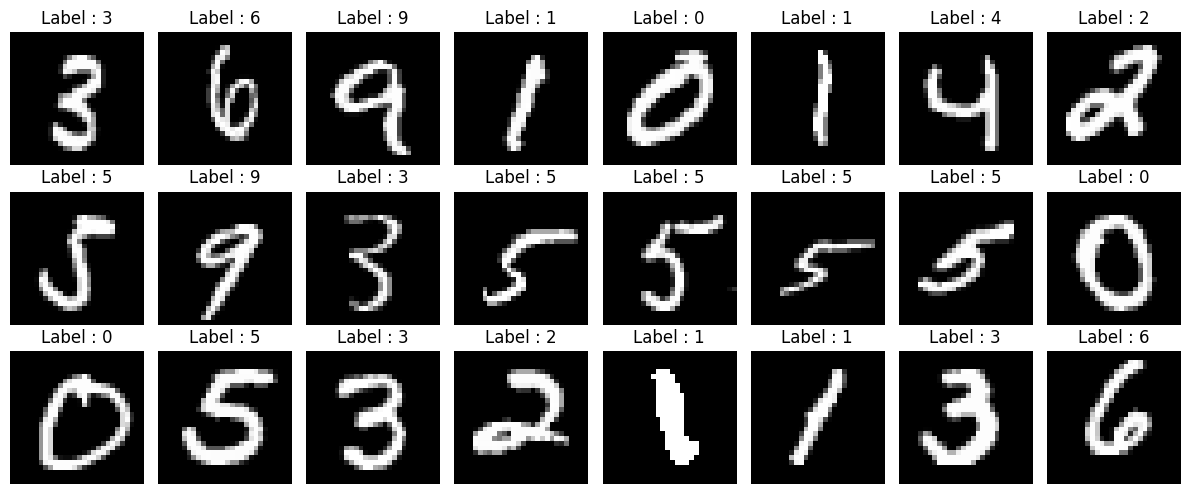

In [ ]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax in axes.flat:
    i = np.random.randint(len(x_train))
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label : {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

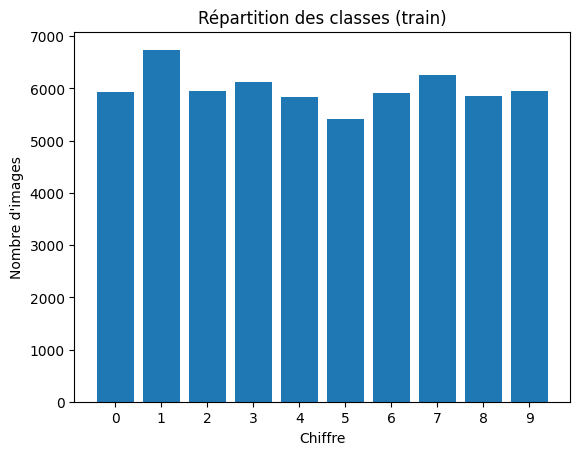

In [ ]:
# Équilibre des classes
classes, counts = np.unique(y_train, return_counts=True)
plt.bar(classes, counts)
plt.xticks(classes)
plt.xlabel("Chiffre"); plt.ylabel("Nombre d'images")
plt.title("Répartition des classes (train)")
plt.show()

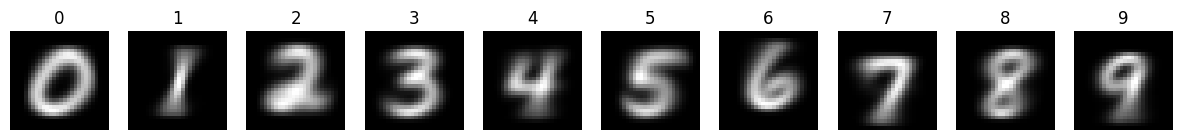

In [ ]:
# Image moyenne par classe : montre la "forme type" de chaque chiffre
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    axes[c].imshow(x_train[y_train == c].mean(axis=0), cmap="gray")
    axes[c].set_title(str(c)); axes[c].axis("off")
plt.show()

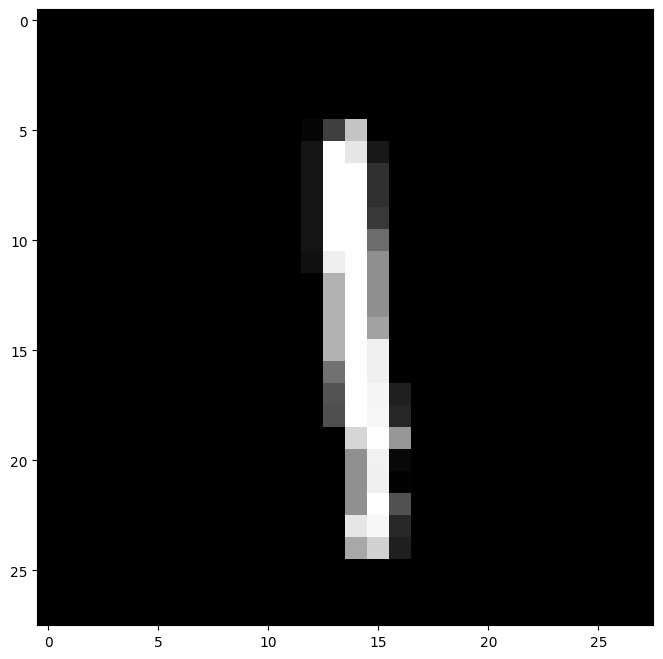

In [ ]:
# Selecte a single sample of the dataset (from 0 to 59 999)
sample_data = 8

# Use this sample to display the image
plt.figure(figsize=(8, 8))
plt.imshow(x_train[sample_data], cmap="gray")

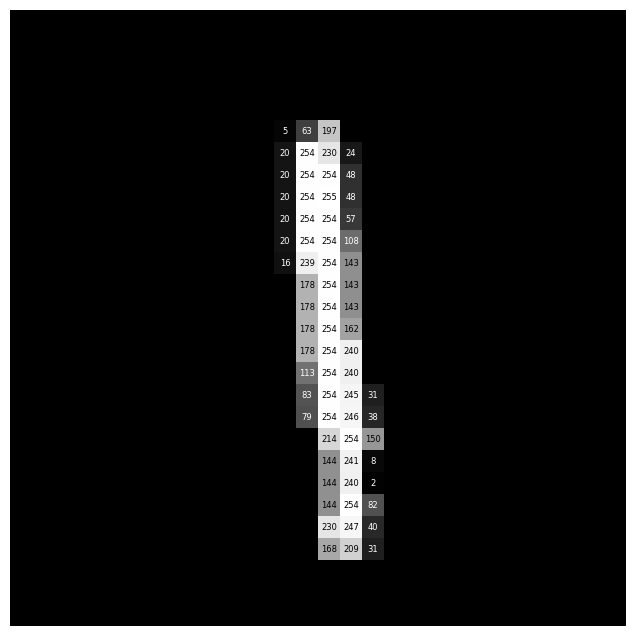

In [ ]:
# Use the same sample to display the image and its pixels values

plt.figure(figsize=(8, 8))
plt.imshow(x_train[sample_data], cmap="gray")
for i in range(28):
    for j in range(28):
        v = x_train[sample_data][i, j]
        if v > 0:
            plt.text(j, i, v, ha="center", va="center", fontsize=6,
                     color="black" if v > 128 else "white")
plt.axis("off"); plt.show()

In [ ]:
!pip install -q mlflow dagshub
import dagshub
import mlflow


REPO_OWNER = "bruno-coulet"
REPO_NAME = "handwritten_digits"

# Authentifie Colab auprès de DagsHub et configure automatiquement MLflow
dagshub.init(repo_owner=REPO_OWNER, repo_name=REPO_NAME, mlflow=True)
mlflow.set_experiment("Palier_1_baseline")

In [ ]:
# Active le logging automatique des métriques Keras (loss, accuracy par époque)
# On met log_models=False pendant l'exploration pour accélérer les runs,
# et on sauvegardera explicitement uniquement le meilleur modèle.
mlflow.tensorflow.autolog(log_models=False)

In [ ]:
import time
import matplotlib.pyplot as plt

config = {
    "architecture": "MLP_784_256_128_10",
    "learning_rate": 1e-3,
    "batch_size": 128,
    "optimizer": "Adam",
    "dropout": 0.2,
    "batch_norm": True,
    "seed": 42
}

with mlflow.start_run(run_name="mlp_2layers_bn_dropout"):
    # 1. Enregistrer les hyperparamètres et métadonnées de reproductibilité
    mlflow.log_params(config)
    mlflow.log_param("iterations_per_epoch", 54000 // config["batch_size"]) #

    # 2. Entraînement du modèle
    start_time = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=config["batch_size"],
        verbose=1
    )
    training_duration = time.time() - start_time

    # 3. Enregistrer les métriques clés de validation (taux d'erreur en %)
    best_val_acc = max(history.history["val_accuracy"])
    val_error_pct = (1.0 - best_val_acc) * 100
    mlflow.log_metric("best_val_error_pct", val_error_pct)
    mlflow.log_metric("training_duration_sec", training_duration)
    mlflow.log_metric("total_params", model.count_params()) # Utile pour la comparaison MLP vs CNN

    # 4. Sauvegarder les courbes d'apprentissage en artefact[cite: 1]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["loss"], label="Train Loss")
    ax[0].plot(history.history["val_loss"], label="Val Loss")
    ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="Train Acc")
    ax[1].plot(history.history["val_accuracy"], label="Val Acc")
    ax[1].legend()
    plt.savefig("learning_curves.png")
    plt.close()

    mlflow.log_artifact("learning_curves.png")

In [ ]:
with mlflow.start_run(run_name="FINAL_BEST_CNN_EVAL"):
    mlflow.set_tag("stage", "milestone_test_eval")

    # Évaluation unique sur le jeu de test (10 000 images)[cite: 1]
    test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
    test_error_pct = (1.0 - test_acc) * 100

    mlflow.log_metric("test_loss", test_loss)
    mlflow.log_metric("test_accuracy", test_acc)
    mlflow.log_metric("test_error_pct", test_error_pct) # Objectif < 2% MLP, < 1% CNN[cite: 1]

    # Sauvegarder le modèle au format .keras et l'uploader sur DagsHub[cite: 1]
    model_path = "best_model.keras"
    best_model.save(model_path)
    mlflow.log_artifact(model_path, artifact_path="model")